# A2组（G21）实验：2.3 数值积分与自动微分；2.4 神经网络逼近与PINN求导

本文件只完成指定两节，2.1、2.2不在此次交付范围。全部量均无量纲。
配套：[正文](A2-G21-正文.md)、[习题](A2组-习题.md)、[参考解答](A2组-习题参考解答.md)。

**运行前预测与规则**：① $x^2$ 的梯形误差为 $1/(6n^2)$，加密误差比为4；② 光滑函数的中心差分先呈二阶下降，过小步长可能放大舍入误差；③ AD对当前计算图求导，不保证网络导数接近目标导数；④ ReLU网络不适合直接按经典二阶导数构造强形式Poisson残差。

**环境与预算**：Python 3.12，CPU，float64，单线程，种子2026；训练配置预先固定为Adam 2000步和L-BFGS最多400次迭代，不按测试集挑模型。一般桌面CPU可运行；以本次实际计时为准。

**独立参考**：积分精确值、纸面解析导数、对已训练权重用NumPy链式法则另算导数。后者只核对AD实现；相对于目标函数的误差另行报告，不能混为一项。

In [1]:
from pathlib import Path
import sys, platform, json, csv, time
import numpy as np
import torch
from torch import nn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
assert (ROOT / 'A2组-实验.ipynb').exists(), '请在Notebook所在目录运行。'
FIG = ROOT / '图片'; DATA = ROOT / '数据'
FIG.mkdir(exist_ok=True); DATA.mkdir(exist_ok=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(2026)
np.random.seed(2026)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'figure.dpi':110})
ENV = dict(python=sys.version.split()[0], numpy=np.__version__, torch=torch.__version__,
           matplotlib=matplotlib.__version__, system=platform.system(), machine=platform.machine(),
           device='CPU', dtype='float64', threads=1, seed=2026)
print(json.dumps(ENV, ensure_ascii=False, indent=2))
METRICS = {'environment':ENV}
def save_csv(name, rows):
    with (DATA / name).open('w', encoding='utf-8-sig', newline='') as f:
        w=csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
def showfig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=180, bbox_inches='tight')
    display(fig); plt.close(fig)

{
  "python": "3.12.10",
  "numpy": "2.5.4",
  "torch": "2.14.1+cpu",
  "matplotlib": "3.11.2",
  "system": "Windows",
  "machine": "AMD64",
  "device": "CPU",
  "dtype": "float64",
  "threads": 1,
  "seed": 2026
}


## 2.3 数值积分与自动微分
### 实验2.3-A：复合梯形积分

输入 $f(x)=x^2$、区间 $[0,1]$、$n=4,8,16,32,64,128$；参考 $I=1/3$。
报告 $|T_n-I|$、前后误差比及 $p=\log_2(E_n/E_{2n})$。
积分实现与精确误差式在float64下应相符至绝对误差 $10^{-14}$；这是一项小规模代数核对，不是任意函数的保证。
另用 $e^x$ 的积分 $e-1$ 检查实现并非只适用于二次多项式。

 n          T_n               abs_error         ratio       order
  4 0.343750000000 1.0416666667e-02      --          --
  8 0.335937500000 2.6041666667e-03   4.0000000  2.0000000
 16 0.333984375000 6.5104166667e-04   4.0000000  2.0000000
 32 0.333496093750 1.6276041667e-04   4.0000000  2.0000000
 64 0.333374023438 4.0690104167e-05   4.0000000  2.0000000
128 0.333343505859 1.0172526042e-05   4.0000000  2.0000000
exp(x) 实测阶: [1.998874 1.999718 1.99993  1.999982 1.999996]


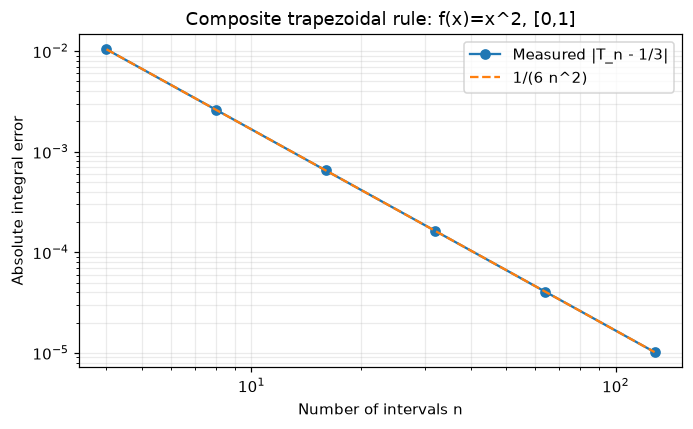

In [2]:
def trapezoid(f, a, b, n):
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError('n必须为正整数')
    x = np.linspace(a, b, n+1)
    y = f(x)
    return (b-a)/n * (0.5*y[0] + y[1:-1].sum() + 0.5*y[-1])

ns = np.array([4,8,16,32,64,128])
quad_rows=[]; previous=None
for n in ns:
    value=trapezoid(lambda x:x*x, 0., 1., int(n))
    err=abs(value-1/3)
    ratio=previous/err if previous is not None else None
    quad_rows.append(dict(n=int(n), T_n=float(value), abs_error=float(err),
                          theory=float(1/(6*n*n)), ratio=ratio,
                          order=float(np.log2(ratio)) if ratio else None))
    previous=err
print(' n          T_n               abs_error         ratio       order')
for r in quad_rows:
    print(f"{r['n']:3d} {r['T_n']:.12f} {r['abs_error']:.10e} " +
          ('     --          --' if r['ratio'] is None else f"{r['ratio']:11.7f} {r['order']:10.7f}"))
assert max(abs(r['abs_error']-r['theory']) for r in quad_rows)<1e-14
assert all(abs(r['order']-2)<1e-7 for r in quad_rows[1:])
assert abs(trapezoid(lambda x:2*x+1, 0., 1., 8)-2.)<1e-14
exp_errors=[abs(trapezoid(np.exp,0.,1.,int(n))-np.expm1(1.)) for n in ns]
exp_orders=np.log2(np.array(exp_errors[:-1])/exp_errors[1:])
assert np.max(np.abs(exp_orders-2))<0.01
print('exp(x) 实测阶:', np.round(exp_orders,6))
save_csv('A2组-积分收敛.csv',quad_rows)
METRICS['quadrature']=quad_rows
METRICS['exp_orders']=exp_orders.tolist()
fig, ax=plt.subplots(figsize=(6.4,4))
ax.loglog(ns,[r['abs_error'] for r in quad_rows], 'o-', label='Measured |T_n - 1/3|')
ax.loglog(ns,1/(6*ns.astype(float)**2),'--',label='1/(6 n^2)')
ax.set(xlabel='Number of intervals n',ylabel='Absolute integral error',title='Composite trapezoidal rule: f(x)=x^2, [0,1]')
ax.grid(True,which='both',alpha=.25);ax.legend()
showfig(fig,'A2组-积分收敛.png')

### 实验2.3-B：同一计算过程的三条求导路线

$F(x)=\sin(x^2)+e^x$，$F'(x)=2x\cos(x^2)+e^x$。
在 $x=0.7$ 比较PyTorch反向AD、手算解析式与中心差分。
步长 $h=10^{-1},\ldots,10^{-16}$；参考与AD差异要求 $<10^{-12}$。
差分不要求所有步长都合格；观察截断误差与舍入误差的竞争。
补充在 $[-1,1]$ 的201点网格核对AD，避免只检验一个点。

解析参考=3.2490187095246466e+00; AD=3.2490187095246466e+00; 差异=0.000e+00
201点网格AD最大误差=4.441e-16
 h             central_difference        abs_error
1e-01   3.2417166809463027e+00   7.302029e-03
1e-02   3.2489460289622629e+00   7.268056e-05
1e-03   3.2490179827533439e+00   7.267713e-07
1e-04   3.2490187022560235e+00   7.268623e-09
1e-05   3.2490187094502683e+00   7.437828e-11
1e-06   3.2490187094058598e+00   1.187868e-10
1e-07   3.2490187074074584e+00   2.117188e-09
1e-08   3.2490187429345951e+00   3.340995e-08
1e-09   3.2490186097078322e+00   9.981681e-08
1e-10   3.2490166113063879e+00   2.098218e-06
1e-11   3.2490232726445356e+00   4.563120e-06
1e-12   3.2489566592630581e+00   6.205026e-05
1e-13   3.2485125700532080e+00   5.061395e-04
1e-14   3.2640556923979602e+00   1.503698e-02
1e-15   3.3306690738754692e+00   8.165036e-02
1e-16   2.2204460492503131e+00   1.028573e+00


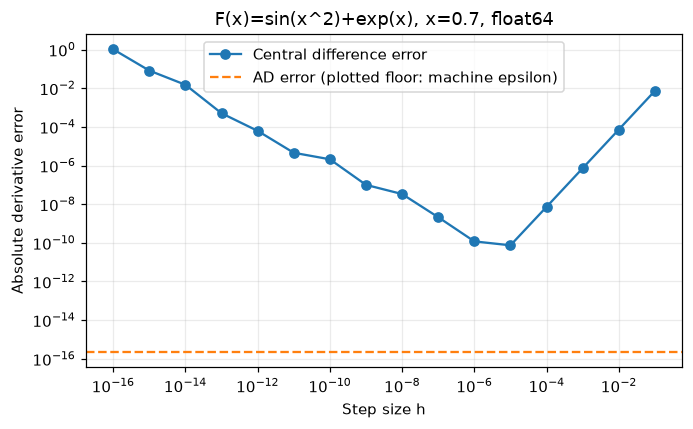

In [3]:
def f_numpy(x): return np.sin(x*x)+np.exp(x)
def fprime_numpy(x): return 2*x*np.cos(x*x)+np.exp(x)
x0=0.7
xt=torch.tensor(x0, requires_grad=True)
yt=torch.sin(xt**2)+torch.exp(xt)
ad=torch.autograd.grad(yt,xt)[0].item()
reference=float(fprime_numpy(x0))
hs=10.**(-np.arange(1,17,dtype=float))
diff_rows=[]
for h in hs:
    df=float((f_numpy(x0+h)-f_numpy(x0-h))/(2*h))
    diff_rows.append(dict(h=float(h), central_difference=df,
                          abs_error=abs(df-reference)))
grid=torch.linspace(-1,1,201,requires_grad=True)
gv=torch.sin(grid**2)+torch.exp(grid)
gd=torch.autograd.grad(gv,grid,grad_outputs=torch.ones_like(gv))[0]
grid_ad_error=float(np.max(np.abs(gd.detach().numpy()-fprime_numpy(grid.detach().numpy()))))
print(f'解析参考={reference:.16e}; AD={ad:.16e}; 差异={abs(ad-reference):.3e}')
print(f'201点网格AD最大误差={grid_ad_error:.3e}')
print(' h             central_difference        abs_error')
for r in diff_rows: print(f"{r['h']:.0e}   {r['central_difference']:.16e}   {r['abs_error']:.6e}")
assert abs(ad-reference)<1e-12 and grid_ad_error<1e-12
save_csv('A2组-差分步长.csv',diff_rows)
METRICS['differentiation']=dict(x=x0,reference=reference,ad=ad,ad_error=abs(ad-reference),
                               grid_ad_error=grid_ad_error,central_difference=diff_rows)
fig,ax=plt.subplots(figsize=(6.4,4))
ax.loglog(hs,[r['abs_error'] for r in diff_rows],'o-',label='Central difference error')
ax.axhline(max(abs(ad-reference),np.finfo(float).eps),ls='--',c='C1',
           label='AD error (plotted floor: machine epsilon)')
ax.set(xlabel='Step size h',ylabel='Absolute derivative error',title='F(x)=sin(x^2)+exp(x), x=0.7, float64')
ax.grid(True,which='both',alpha=.25);ax.legend()
showfig(fig,'A2组-差分步长.png')

**解释**：上述积分误差来自分段直线替代曲线；差分误差来自差商截断与浮点相减。
AD使用原计算图的局部导数，不选差分步长。数值恰巧相等仅表示此例在所用精度下吻合，不表示AD消除了所有舍入误差。

## 2.4 AI关联：神经网络逼近与PINN求导
### 实验2.4-A：小网络拟合与独立导数评价

目标 $g(x)=\sin(\pi x)$，$g'=\pi\cos(\pi x)$，$g''=-\pi^2\sin(\pi x)$。
训练41个等距点；测试400个均匀小区间的中点，与训练点严格不重合；端点单独检查。
网络为1–32–32–1、两层tanh；只最小化函数值MSE，不给导数标签，不使用PDE残差训练。
训练方案在测试前固定。函数值达到最大绝对误差 $10^{-2}$ 视为此教学拟合达到幅值1的百分之一；
此阈值不用于宣称PINN达标。一、二阶导数与残差只如实报告。

In [4]:
torch.manual_seed(2026)
model=nn.Sequential(nn.Linear(1,32),nn.Tanh(),nn.Linear(32,32),nn.Tanh(),nn.Linear(32,1))
x_train=torch.linspace(-1,1,41).reshape(-1,1)
y_train=torch.sin(torch.pi*x_train)
x_test_np=-1+(np.arange(400)+0.5)*2/400
assert np.min(np.abs(x_test_np[:,None]-x_train.numpy().ravel()[None,:]))>1e-12
history=[]
t_start=time.perf_counter()
opt=torch.optim.Adam(model.parameters(), lr=1e-3)
for step in range(2000):
    opt.zero_grad()
    loss=((model(x_train)-y_train)**2).mean()
    loss.backward(); opt.step()
    if step%100==0 or step==1999:
        history.append(dict(stage='Adam',step=step+1,mse=float(loss.detach())))
lbfgs=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=400,max_eval=500,
                      tolerance_grad=1e-12,tolerance_change=1e-14,
                      history_size=50,line_search_fn='strong_wolfe')
closure_count=0
def closure():
    global closure_count
    lbfgs.zero_grad()
    loss=((model(x_train)-y_train)**2).mean()
    loss.backward(); closure_count+=1
    if closure_count%20==0:
        history.append(dict(stage='LBFGS',step=closure_count,mse=float(loss.detach())))
    return loss
lbfgs.step(closure)
elapsed=time.perf_counter()-t_start
train_mse=float(((model(x_train)-y_train)**2).mean().detach())
print(f'参数数={sum(p.numel() for p in model.parameters())}; CPU训练秒数={elapsed:.3f}')
print(f'最终训练MSE={train_mse:.6e}; LBFGS闭包次数={closure_count}')
save_csv('A2组-训练过程.csv',history)

参数数=1153; CPU训练秒数=2.201
最终训练MSE=4.531542e-08; LBFGS闭包次数=469


 quantity        max_abs_error       RMSE               relative_L2
u            4.13504964e-04   2.14081598e-04   3.02757100e-04
du_dx        1.52278524e-02   4.26419747e-03   1.91956328e-03
d2u_dx2      3.56212765e-01   9.23909872e-02   1.32386853e-02
NumPy链式法则 vs AD 最大差异(u, ux, uxx): [4.440892098500626e-16, 1.3322676295501878e-15, 7.105427357601002e-15]
Poisson残差RMSE=9.23909872e-02; 边界预测=[-1.48538029e-04  4.51552530e-05]
残差损失参数梯度范数=5.22350218e-01; 不依赖的参数组数=1


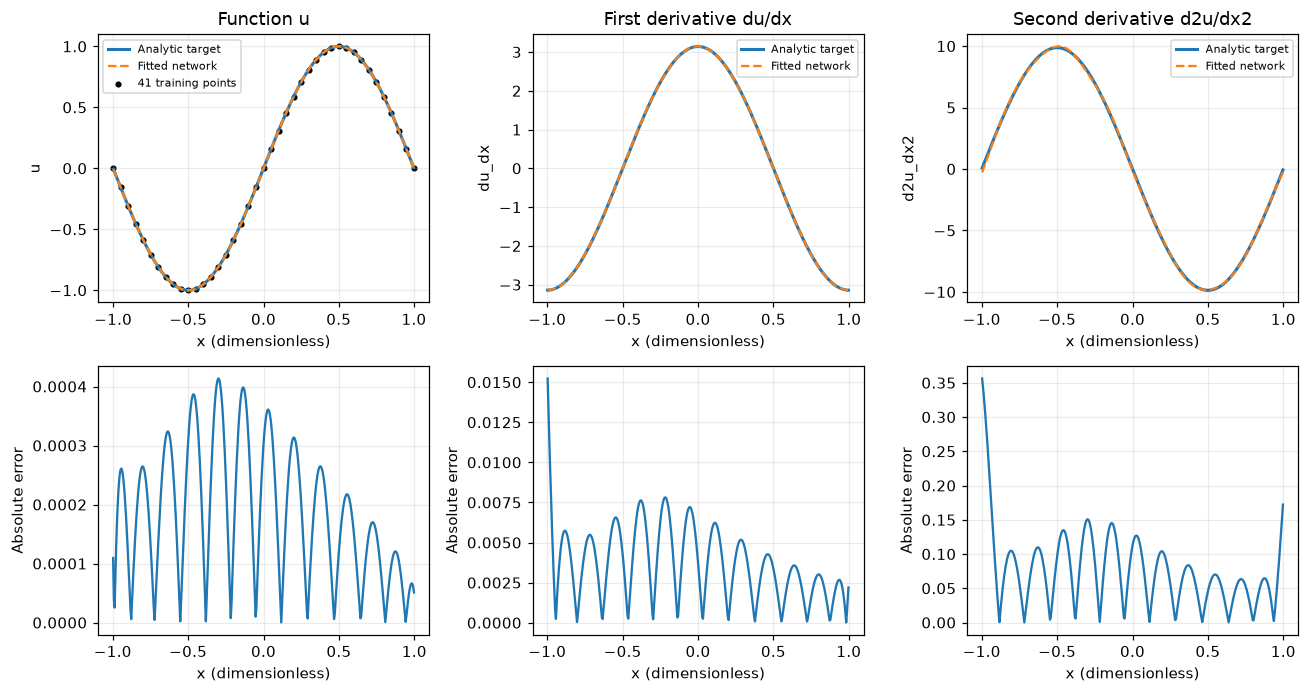

In [5]:
def input_derivatives(model, values):
    x=torch.tensor(values,dtype=torch.float64).reshape(-1,1).requires_grad_(True)
    y=model(x)
    dy=torch.autograd.grad(y,x,torch.ones_like(y),create_graph=True)[0]
    d2y=torch.autograd.grad(dy,x,torch.ones_like(dy),create_graph=True)[0]
    return x,y,dy,d2y

x_test,u,ux,uxx=input_derivatives(model,x_test_np)
pred=[v.detach().numpy().ravel() for v in (u,ux,uxx)]
truth=[np.sin(np.pi*x_test_np),np.pi*np.cos(np.pi*x_test_np),
       -np.pi**2*np.sin(np.pi*x_test_np)]
names=['u','du_dx','d2u_dx2']; eval_rows=[]
for name,p,t in zip(names,pred,truth):
    eval_rows.append(dict(quantity=name,max_abs_error=float(np.max(np.abs(p-t))),
                          rmse=float(np.sqrt(np.mean((p-t)**2))),
                          relative_l2=float(np.linalg.norm(p-t)/np.linalg.norm(t))))
print(' quantity        max_abs_error       RMSE               relative_L2')
for r in eval_rows: print(f"{r['quantity']:12s} {r['max_abs_error']:.8e}   {r['rmse']:.8e}   {r['relative_l2']:.8e}")
assert eval_rows[0]['max_abs_error']<1e-2, '如失败，记录真实训练结果而非修改测试点。'
save_csv('A2组-网络误差.csv',eval_rows)

# 对相同已训练权重，用NumPy另写链式法则；不调用torch.autograd。
layers=[model[0],model[2],model[4]]
weights=[(layer.weight.detach().numpy(),layer.bias.detach().numpy()) for layer in layers]
z=x_test_np[:,None]; dz=np.ones_like(z); d2z=np.zeros_like(z)
for k,(w,b) in enumerate(weights):
    a=z@w.T+b; da=dz@w.T; d2a=d2z@w.T
    if k<2:
        z=np.tanh(a); s=1-z*z
        dz=s*da; d2z=s*d2a-2*z*s*da*da
    else:
        z,dz,d2z=a,da,d2a
manual_errors=[float(np.max(np.abs(a.ravel()-b))) for a,b in zip((z,dz,d2z),pred)]
assert max(manual_errors)<1e-10
print('NumPy链式法则 vs AD 最大差异(u, ux, uxx):',manual_errors)

# 仅评价一维Poisson残差，不以它更新权重。
# -u_xx = pi^2 sin(pi*x), x in (-1,1); u(-1)=u(1)=0。
r=-pred[2]-np.pi**2*np.sin(np.pi*x_test_np)
residual_rmse=float(np.sqrt(np.mean(r*r)))
boundary=model(torch.tensor([[-1.],[1.]])).detach().numpy().ravel()
print(f'Poisson残差RMSE={residual_rmse:.8e}; 边界预测={boundary}')
# 确认二阶输入导数的图仍可对参数传播；这里不进行残差优化。
res_loss=((-uxx-torch.pi**2*torch.sin(torch.pi*x_test))**2).mean()
parameter_grads=torch.autograd.grad(res_loss,tuple(model.parameters()),allow_unused=True)
grad_norm=float(torch.sqrt(sum((v*v).sum() for v in parameter_grads if v is not None)))
print(f'残差损失参数梯度范数={grad_norm:.8e}; 不依赖的参数组数={sum(v is None for v in parameter_grads)}')
assert np.isfinite(grad_norm)

METRICS['network']=dict(architecture='1-32-32-1, tanh',parameters=1153,train_points=41,
    test_points=400,train_mse=train_mse,adam_steps=2000,lbfgs_max_iter=400,
    lbfgs_closures=closure_count,seconds=elapsed,errors=eval_rows,
    ad_manual_errors=manual_errors,poisson_residual_rmse=residual_rmse,
    boundary_values=boundary.tolist(),residual_parameter_gradient_norm=grad_norm)
save_csv('A2组-测试点与导数.csv',[
    dict(x=float(x),u=float(a),ux=float(b),uxx=float(c),target=float(t),
         target_dx=float(d),target_dxx=float(e),residual=float(rr))
    for x,a,b,c,t,d,e,rr in zip(x_test_np,*pred,*truth,r)])
torch.save(model.state_dict(),DATA/'A2组-网络权重.pt')
fig,axs=plt.subplots(2,3,figsize=(12,6.4))
labels=['Function u','First derivative du/dx','Second derivative d2u/dx2']
for j in range(3):
    axs[0,j].plot(x_test_np,truth[j],label='Analytic target',lw=2)
    axs[0,j].plot(x_test_np,pred[j],'--',label='Fitted network')
    if j==0: axs[0,j].scatter(x_train.numpy(),y_train.numpy(),s=9,c='k',label='41 training points')
    axs[0,j].set(title=labels[j],xlabel='x (dimensionless)',ylabel=names[j]);axs[0,j].legend(fontsize=7)
    axs[1,j].plot(x_test_np,np.abs(pred[j]-truth[j]))
    axs[1,j].set(xlabel='x (dimensionless)',ylabel='Absolute error')
    for i in range(2):axs[i,j].grid(alpha=.25)
showfig(fig,'A2组-网络与导数.png')

### 实验2.4-B：可控反例与激活函数光滑性

教学构造 $v_k(x)=\sin(\pi x)+k^{-1}\sin(kx)$，$k=10,100,1000$。
虽然函数最大误差不超过 $1/k$，但导数差在 $x=0$ 恰为1；二阶导数差在 $x=\pi/(2k)$ 的大小恰为 $k$。
这是在指定位置的解析反例，不冒充网络训练输出；有限网格不保证找到全区间最大值。

另考察 $v(x)=\mathrm{ReLU}(x)$。在非零点AD二阶导数为0，在0点经典一阶导数不存在；框架在0返回的约定值不是经典导数存在的证明。

高频扰动反例: [{"k": 10, "value_error_at_witness": 0.1, "first_error_at_zero": 1.0, "second_error_at_witness": 10.0}, {"k": 100, "value_error_at_witness": 0.01, "first_error_at_zero": 1.0, "second_error_at_witness": 100.0}, {"k": 1000, "value_error_at_witness": 0.001, "first_error_at_zero": 1.0, "second_error_at_witness": 1000.0}]
ReLU x: [-0.5  0.   0.5]  框架一阶: [0. 0. 1.]  框架二阶: [0. 0. 0.]


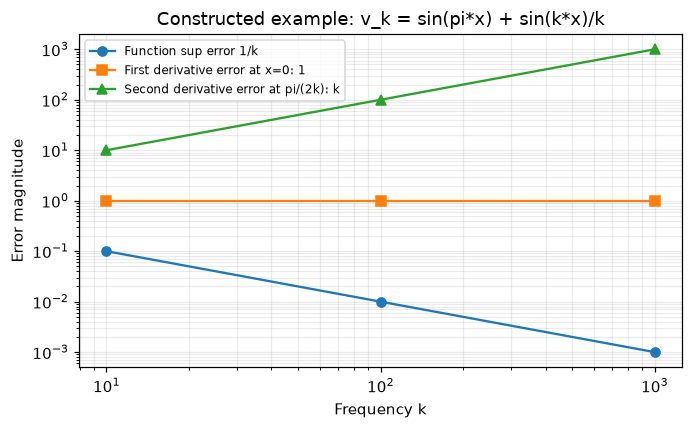

全部实验执行完成；表、图、权重与实测摘要均已保存。


In [6]:
counter_rows=[]
for k in [10,100,1000]:
    x_witness=np.pi/(2*k)
    value_error=abs(np.sin(k*x_witness)/k)
    first_error_at_zero=abs(np.cos(0.))
    second_error_at_witness=abs(-k*np.sin(k*x_witness))
    counter_rows.append(dict(k=k,value_error_at_witness=float(value_error),
                             first_error_at_zero=float(first_error_at_zero),
                             second_error_at_witness=float(second_error_at_witness)))
print('高频扰动反例:',json.dumps(counter_rows,ensure_ascii=False))
rx=torch.tensor([-0.5,0.,0.5],requires_grad=True)
ry=torch.relu(rx)
rd=torch.autograd.grad(ry,rx,torch.ones_like(ry),create_graph=True)[0]
rdd=torch.autograd.grad(rd,rx,torch.ones_like(rd))[0]
print('ReLU x:',rx.detach().numpy(),' 框架一阶:',rd.detach().numpy(),' 框架二阶:',rdd.detach().numpy())
assert torch.equal(rdd,torch.zeros_like(rdd))
METRICS['counterexample']=counter_rows
save_csv('A2组-高频反例.csv',counter_rows)
fig,ax=plt.subplots(figsize=(6.4,4))
ks=[r['k'] for r in counter_rows]
ax.loglog(ks,[1/k for k in ks],'o-',label='Function sup error 1/k')
ax.loglog(ks,[1.]*len(ks),'s-',label='First derivative error at x=0: 1')
ax.loglog(ks,ks,'^-',label='Second derivative error at pi/(2k): k')
ax.set(xlabel='Frequency k',ylabel='Error magnitude',title='Constructed example: v_k = sin(pi*x) + sin(k*x)/k')
ax.legend(fontsize=8);ax.grid(True,which='both',alpha=.25)
showfig(fig,'A2组-高频反例.png')
(DATA/'A2组-实测摘要.json').write_text(json.dumps(METRICS,ensure_ascii=False,indent=2),encoding='utf-8')
print('全部实验执行完成；表、图、权重与实测摘要均已保存。')

### 实际运行解释与边界

1. 积分表与精确误差式交叉核对，$e^x$ 的独立例子也呈二阶收敛；仅涵盖一维、等距、小规模光滑例子。
2. 差分曲线低谷和回升的位置依赖精度与平台；解析式与AD之差很小并不能推广为任意程序的“无误差求导”。
3. 训练MSE、独立网格函数误差与导数误差分别报告；NumPy链式法则验证的是网络导数实现，目标解析导数验证的是逼近质量。
4. 此处只对已拟合网络计算Poisson残差并检查参数梯度链路，未用残差训练，未完成PINN/PDE求解。缺少足够光滑性时，强形式二阶残差也会失去经典意义。
5. 当前MLP各样本独立，`grad_outputs=ones`才可提取逐点输入导数；若网络跨样本耦合，须重新分析Jacobian。

来源：本地误差与插值课件（具体页码见正文）；[Baydin等，2018](https://jmlr.org/papers/v18/17-468.html)；[PyTorch autograd.grad](https://docs.pytorch.org/docs/2.14/generated/torch.autograd.grad.html)；[Raissi等，2017](https://arxiv.org/abs/1711.10561)。

**真实性**：代码与文字由Codex辅助生成并在本机执行；学生人工核验、B/C独立复现尚未发生，不作已完成声明。